<h1 align="center">Лабораторна робота №2</h1>
<h2 align="center">Зниження розмірності, кластеризація та класифікація текстових даних</h2>

## Мета роботи
Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.

## Завдання
1. Зниження розмірності та візуалізація даних
Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
Застосуйте `sklearn.decomposition.PCA` для зниження розмірності даних. На отриманих даних навчіть один з алгоритмів класифікації з Lab 1 та порівняйте результати класифікації "до" та "після" PCA.
Зробіть висновки: як PCA вплинув на якість класифікації; наскільки вдалося зменшити кількість ознак; чи змінився час навчання моделі.
Для того самого датасету застосуйте `sklearn.manifold.TSNE` для зниження розмірності до 2D. Візуалізуйте отримані дані, використовуючи кольори для позначення класів, та поясніть результат.
2. Кластерний аналіз
Візьміть датасет з лабораторної роботи №1. Не використовуйте мітки класів (target) під час кластеризації.
Виконайте кластеризацію даних за допомогою алгоритму K-Means.  Визначте доцільну кількість кластерів за допомогою Elbow Method та/або Silhouette Score.  Візуалізуйте отримані кластери у 2D за допомогою PCA або t-SNE. Після виконання кластеризації порівняйте отримані кластери зі справжніми класами датасету.  Зробіть висновок: чи відповідає знайдена кластерна структура реальним класам?
Якщо датасет містить велику кількість класів, для спрощення аналізу можна залишити 2–3 класи, обґрунтувавши свій вибір.
Важливо: кластер і клас — не одне й те саме. Не очікується, що K-Means обов'язково відтворить початкові класи датасету. Потрібно проаналізувати та пояснити отриманий результат.
3. Обробка та класифікація текстових даних
Завантажте набір текстових даних з мітками класів. Проведіть передобробку текстів (наприклад, видалення стоп-слів та пунктуації). За допомогою WordCloud візуалізуйте найбільш характерні слова/словосполучення для кожного класу та поясніть отримані результати. Векторизуйте тексти, наприклад за допомогою `sklearn.feature_extraction.text.TfidfVectorizer`.
Навчіть модель класифікації текстів та оцініть якість класифікації за відповідними метриками.

## Хід роботи

Обраний мною датасет з 1 лабораторної: https://archive.ics.uci.edu/dataset/542/internet+firewall+data

Використовую Internet Firewall Data - набір записів мережевого трафіку з журналу університетського фаєрвола.

Блок імпортів:

In [28]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, f1_score
from sklearn.manifold import TSNE
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from time import perf_counter
from wordcloud import WordCloud, STOPWORDS

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import confusion_matrix

from sklearn.metrics import classification_report

import csv

## Робота з датасетом
Завантажую дані та переглядаю перші 5 рядків.

In [29]:
df = pd.read_csv('../Datasets/log2.csv')

X = df.drop(columns=["Action"])
y = df["Action"]

print("Розмір датасета:", df.shape)
print("Кількість вхідних ознак:", X.shape[1])

print("\nКількість записів кожного класу:")
print(y.value_counts())

df.head()

Розмір датасета: (65532, 12)
Кількість вхідних ознак: 11

Кількість записів кожного класу:
Action
allow         37640
deny          14987
drop          12851
reset-both       54
Name: count, dtype: int64


,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


### Завдання 1. Зниження розмірності та візуалізація даних

Дослідимо, як PCA впливає на кількість ознак, якість класифікації та час навчання. Окремо будуємо 2D-візуалізацію за допомогою t-SNE.


Для порівняння використовуємо Decision Tree, тому що воно в минулій лабораторній роботі дало найкращий результат, з однаковими параметрами до та після PCA.

Розділяємо дані на навчальну й тестову вибірки у співвідношенні 80/20 зі збереженням пропорцій класів. Масштабування та PCA навчаємо лише на навчальній вибірці.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7, stratify=y)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (52425, 11)
Тестова вибірка: (13107, 11)


In [31]:
tree_before_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(random_state=7))])

tree_after_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, svd_solver="full")),
    ("model", DecisionTreeClassifier(random_state=7))])

Навчаємо обидва Pipeline. Вимірюємо загальний час виконання fit: він включає масштабування, навчання дерева та, для другого варіанта, обчислення PCA.

Кроки:
- Без PCA: обчислюємо масштабування -> масштабуємо дані -> навчаємо дерево
- З PCA: обчислюємо масштабування -> масштабуємо дані -> навчаємо PCA й отримуємо компоненти -> навчаємо дерево на компонентах


In [32]:
start_time = perf_counter()
tree_before_pca.fit(X_train, y_train)
time_before_pca = perf_counter() - start_time

start_time = perf_counter()
tree_after_pca.fit(X_train, y_train)
time_after_pca = perf_counter() - start_time

print(f"Час навчання Pipeline без PCA: {time_before_pca:.4f} с")
print(f"Час навчання Pipeline із PCA: {time_after_pca:.4f} с")

Час навчання Pipeline без PCA: 0.1842 с
Час навчання Pipeline із PCA: 0.5085 с


Перевіряємо кількість компонент:

In [33]:
pca_step = tree_after_pca.named_steps["pca"]

original_features = X_train.shape[1]
remaining_components = pca_step.n_components_
retained_variance = pca_step.explained_variance_ratio_.sum()

print("Початкова кількість ознак:", original_features)
print("Кількість компонент після PCA:", remaining_components)
print(f"Зменшення кількості вимірів: {original_features - remaining_components}")
print(f"Збережена частка дисперсії: {retained_variance:.2%}")

Початкова кількість ознак: 11
Кількість компонент після PCA: 6
Зменшення кількості вимірів: 5
Збережена частка дисперсії: 95.96%


PCA зменшив кількість вимірів із 11 до 6, але навчання всього Pipeline стало повільнішим.

Порівняємо якість класифікації до та після PCA на однаковій тестовій вибірці. Основну увагу приділяємо macro-F1, оскільки класи незбалансовані. Додатково аналізуємо accuracy та показники кожного класу.

In [34]:
predictions_before_pca = tree_before_pca.predict(X_test)
predictions_after_pca = tree_after_pca.predict(X_test)

class_order = ["allow", "deny", "drop", "reset-both"]

print("Дерево без PCA:")
print(classification_report(y_test, predictions_before_pca, labels=class_order, digits=4, zero_division=0))

print("Дерево після PCA:")
print(classification_report(y_test, predictions_after_pca, labels=class_order, digits=4, zero_division=0))

Дерево без PCA:
              precision    recall  f1-score   support

       allow     1.0000    0.9992    0.9996      7528
        deny     0.9920    0.9963    0.9942      2998
        drop     0.9973    0.9949    0.9961      2570
  reset-both     0.6000    0.5455    0.5714        11

    accuracy                         0.9973     13107
   macro avg     0.8973    0.8840    0.8903     13107
weighted avg     0.9973    0.9973    0.9973     13107

Дерево після PCA:
              precision    recall  f1-score   support

       allow     0.9995    0.9988    0.9991      7528
        deny     0.9907    0.9950    0.9928      2998
        drop     0.9965    0.9953    0.9959      2570
  reset-both     0.1667    0.0909    0.1176        11

    accuracy                         0.9965     13107
   macro avg     0.7883    0.7700    0.7764     13107
weighted avg     0.9962    0.9965    0.9963     13107



In [35]:
pca_comparison = pd.DataFrame({
    "Варіант": ["Без PCA", "Із PCA"],
    "Кількість ознак / компонент": [original_features, remaining_components],
    "Accuracy": [
        accuracy_score(y_test, predictions_before_pca),
        accuracy_score(y_test, predictions_after_pca)],
    "Macro-F1": [
        f1_score(y_test, predictions_before_pca, average="macro", zero_division=0),
        f1_score(y_test, predictions_after_pca, average="macro", zero_division=0)],
    "Час навчання Pipeline, с": [time_before_pca, time_after_pca]
})

pca_comparison.round(4)

,Варіант,Кількість ознак / компонент,Accuracy,Macro-F1,"Час навчання Pipeline, с"
0,Без PCA,11,0.9973,0.8903,0.1842
1,Із PCA,6,0.9965,0.7764,0.5085


Якість дерева рішень погіршується: accuracy знижується з 99,73% до 99,65%, а macro-F1 - з 0,8903 до 0,7764.
Найбільше погіршується розпізнавання reset-both: без PCA правильно визначаємо 6 із 11 записів, після PCA лише 1.

Можливе пояснення полягає в тому, що PCA не використовує мітки класів і може відкинути відмінності, важливі для класифікації. Також нові компоненти можуть бути менш зручними для порогових розділень дерева, ніж початкові ознаки.

Загальний час навчання Pipeline збільшується з 0,1842 до 0,5085 секунди. Цей час включає підготовку даних і навчання дерева, тому не характеризує швидкість лише класифікатора.

Отже, для обраного дерева й налаштування PCA скорочення кількості вимірів не дає переваги за якістю та загальним часом навчання. Результат стосується цього експерименту; оцінка рідкісного класу ґрунтується лише на 11 тестових записах.

#### Візуалізація даних за допомогою t-SNE

Для візуалізації обираємо стратифіковану підвибірку з 5000 записів. Це зменшує час обчислення та кількість точок, які перекриваються на графіку.

Масштабуємо ознаки, оскільки t-SNE використовує відстані між записами. Цільову змінну Action не включаємо до ознак:
використовуємо її для формування підвибірки та позначення класів кольорами.

In [36]:
X_tsne, _, y_tsne, _ = train_test_split(X, y, train_size=5000, stratify=y, random_state=7)

tsne_scaler = StandardScaler()
X_tsne_scaled = tsne_scaler.fit_transform(X_tsne)

print("Розмір підвибірки:", X_tsne.shape)
print("\nКількість записів кожного класу:")
print(y_tsne.value_counts())

Розмір підвибірки: (5000, 11)

Кількість записів кожного класу:
Action
allow         2872
deny          1143
drop           981
reset-both       4
Name: count, dtype: int64


In [37]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=7)

start_time = perf_counter()

tsne_coordinates = tsne.fit_transform(X_tsne_scaled)

tsne_time = perf_counter() - start_time

print("Розмір результату:", tsne_coordinates.shape)
print(f"Час обчислення t-SNE: {tsne_time:.2f} с")

Розмір результату: (5000, 2)
Час обчислення t-SNE: 22.67 с


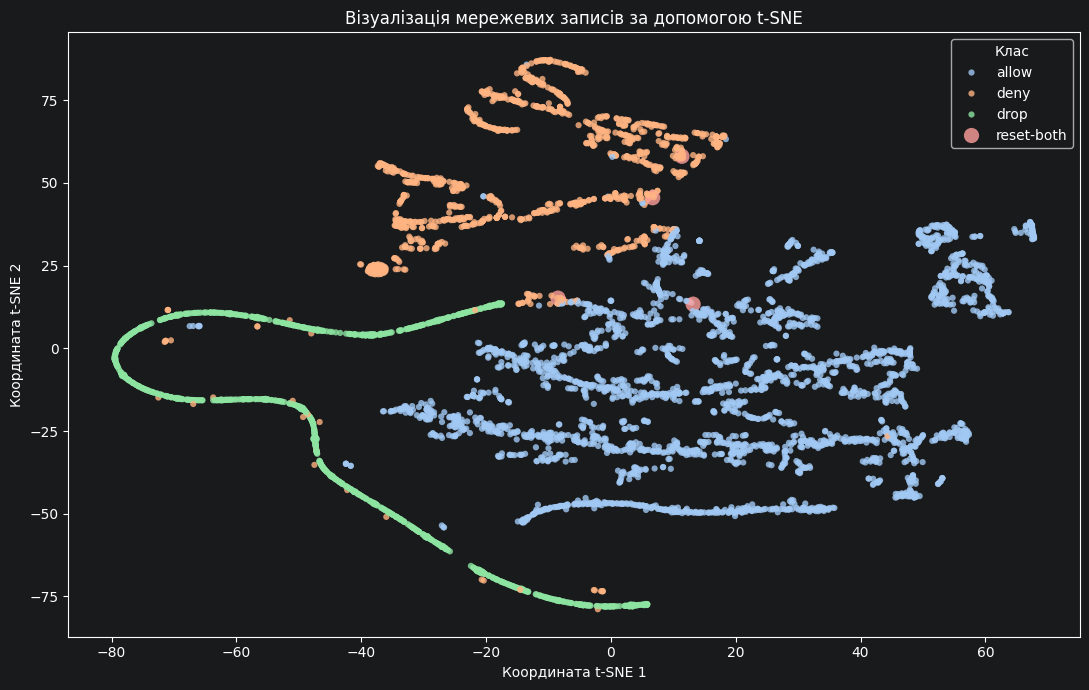

In [38]:
tsne_plot_data = pd.DataFrame({
    "Координата 1": tsne_coordinates[:, 0],
    "Координата 2": tsne_coordinates[:, 1],
    "Клас": y_tsne.to_numpy()})

plt.figure(figsize=(11, 7))

sns.scatterplot(data=tsne_plot_data, x="Координата 1", y="Координата 2",
                hue="Клас", hue_order=class_order, palette="pastel",
                size="Клас", sizes={"allow": 20, "deny": 20, "drop": 20, "reset-both": 120},
                alpha=0.8, linewidth=0, legend="full")

plt.title("Візуалізація мережевих записів за допомогою t-SNE")
plt.xlabel("Координата t-SNE 1")
plt.ylabel("Координата t-SNE 2")
plt.tight_layout()
plt.show()

На графіку спостерігаємо часткове розділення класів. Записи allow переважають у центральній і правій частинах, deny у верхній, а drop утворює виразну область ліворуч і внизу. Водночас окремі записи різних класів розташовані поруч, тому повного розділення не спостерігаємо.

Чотири записи reset-both не утворюють помітної окремої групи та розташовані поблизу областей allow і deny. Через малу кількість цих записів не узагальнюємо спостереження на весь клас. Це узгоджується з тим, що моделі часто плутали цей клас з іншими.

t-SNE використовуємо для дослідження локального сусідства. Форму областей і великі відстані між ними не трактуємо як точне відображення структури початкових даних.

### Завдання 2. Кластерний аналіз

Виконуємо кластеризацію всіх записів Internet Firewall Data за 11 вхідними ознаками. Мітки Action під час навчання K-Means і вибору кількості кластерів не використовуємо.

Перед кластеризацією масштабуємо ознаки за допомогою StandardScaler, оскільки K-Means використовує відстані. Для вибору кількості кластерів застосовуємо метод ліктя.

In [39]:
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X)

cluster_counts = list(range(1, 9))
inertias = []

for k in cluster_counts:
    kmeans_candidate = KMeans(n_clusters=k, n_init=10, random_state=7)
    kmeans_candidate.fit(X_cluster_scaled)
    inertias.append(kmeans_candidate.inertia_)

elbow_results = pd.DataFrame({
    "Кількість кластерів": cluster_counts,
    "Інерція": inertias})

elbow_results

,Кількість кластерів,Інерція
0,1,720852.000000
1,2,479028.242411
2,3,381589.425514
3,4,303542.636667
4,5,237987.282785
5,6,195774.136714
6,7,159390.318577
7,8,135801.427106


Побудуємо графік інерції для кількості кластерів від 1 до 8.
Інерція - це сума квадратів відстаней від записів до центрів їхніх кластерів. Менше значення означає компактніші групи.

Зі збільшенням кількості кластерів інерція зазвичай зменшується. Тому шукаємо "лікоть" - місце, після якого додавання кластерів дає значно менше покращення.

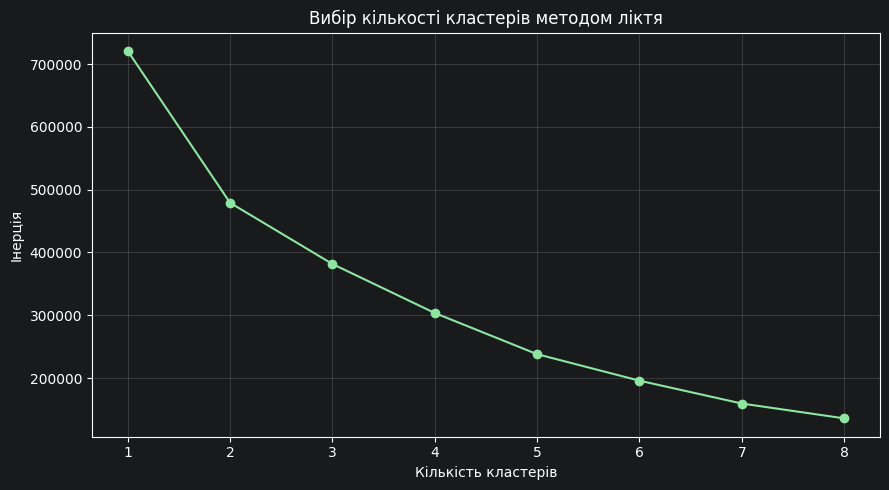

In [40]:
plt.figure(figsize=(9, 5))

plt.plot(cluster_counts, inertias, marker="o", color=sns.color_palette("pastel")[2])

plt.title("Вибір кількості кластерів методом ліктя")
plt.xlabel("Кількість кластерів")
plt.ylabel("Інерція")
plt.xticks(cluster_counts)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Найбільше зменшення інерції спостерігаємо при переході від одного до двох кластерів: із 720852 до приблизно 479028.
Після `k=2` спад стає плавнішим, проте інерція продовжує суттєво зменшуватися.

Розглядаємо `k=2` як можливий варіант, але однозначного "ліктя" не спостерігаємо. Для уточнення кількості кластерів додатково порівняємо Silhouette Score для k від 2 до 8.
Silhouette Score оцінює, наскільки добре запис потрапив у свій кластер порівняно із сусідніми кластерами.

Для k від 2 до 8 обчислюємо Silhouette Score. Він оцінює компактність кластерів та їхню відокремленість.

K-Means навчаємо на всіх масштабованих записах. Для прискорення Silhouette Score оцінюємо на однаковій випадковій підвибірці з 5000 записів. Додатково перевіряємо розмір найменшого кластера та кількість кластерів, представлених у підвибірці. Мітки Action не використовуємо.

In [41]:
rng = np.random.default_rng(7)
sample_indices = rng.choice(len(X_cluster_scaled), size=5000, replace=False)
X_silhouette_sample = X_cluster_scaled[sample_indices]

silhouette_results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=7)
    cluster_labels = model.fit_predict(X_cluster_scaled)

    sample_labels = cluster_labels[sample_indices]
    represented_clusters = len(np.unique(sample_labels))

    if 2 <= represented_clusters < len(sample_labels):
        score = silhouette_score(X_silhouette_sample, sample_labels)
    else:
        score = np.nan

    silhouette_results.append({
        "Кількість кластерів": k,
        "Silhouette Score": score,
        "Найменший кластер, записів": pd.Series(cluster_labels).value_counts().min(),
        "Кластерів у підвибірці": represented_clusters})

silhouette_table = pd.DataFrame(silhouette_results)
silhouette_table.round(4)

,Кількість кластерів,Silhouette Score,"Найменший кластер, записів",Кластерів у підвибірці
0,2,NaN,1,1
1,3,NaN,1,1
2,4,0.4546,1,2
3,5,0.4608,1,3
4,6,0.4284,1,4
5,7,0.4377,1,5
6,8,0.4729,1,6


Під час аналізу Silhouette Score виявляємо обмеження випадкової підвибірки: для кожного k частина кластерів у ній відсутня.
Для `k=2` та `k=3` представлений лише один кластер, тому оцінку неможливо обчислити.

При `k=2` отримуємо кластер із 65531 записів та окремий кластер з одного запису. Це показує, що вигин на графіку інерції не обов'язково відповідає змістовному поділу основної маси даних.

Найбільший обчислений Silhouette Score отримуємо при `k=8`, але в підвибірці представлені лише 6 із 8 кластерів. Тому остаточну кількість кластерів поки не визначаємо.

Тепер зробимо кластеризацію після логарифмічного перетворення

У початковому експерименті отримуємо дуже маленькі кластери, зокрема кластер з одного запису. Перевіряємо, як зміниться результат після зменшення впливу великих значень.

До обсягів даних, кількості пакетів і тривалості застосовуємо log(1 + значення), після чого масштабуємо всі ознаки.
Порти не логарифмуємо. Записи не видаляємо.

In [42]:
traffic_features = ["Bytes", "Bytes Sent", "Bytes Received",
                    "Packets", "Elapsed Time (sec)", "pkts_sent", "pkts_received"]

X_cluster_log = X.copy()
X_cluster_log[traffic_features] = np.log1p(X_cluster_log[traffic_features])

log_cluster_scaler = StandardScaler()
X_cluster_log_scaled = log_cluster_scaler.fit_transform(X_cluster_log)

print("Розмір даних після перетворення:", X_cluster_log_scaled.shape)

Розмір даних після перетворення: (65532, 11)


In [43]:
log_clustering_results = []
log_kmeans_models = {}

for k in range(1, 9):
    candidate = KMeans(n_clusters=k, n_init=10, random_state=7)
    labels = candidate.fit_predict(X_cluster_log_scaled)

    log_kmeans_models[k] = candidate

    sample_labels = labels[sample_indices]
    represented_clusters = len(np.unique(sample_labels))

    if 2 <= represented_clusters < len(sample_labels):
        score = silhouette_score(
            X_cluster_log_scaled[sample_indices],
            sample_labels
        )
    else:
        score = np.nan

    log_clustering_results.append({
        "Кількість кластерів": k,
        "Інерція": candidate.inertia_,
        "Silhouette Score": score,
        "Найменший кластер, записів": pd.Series(labels).value_counts().min(),
        "Кластерів у підвибірці": represented_clusters})

log_clustering_table = pd.DataFrame(log_clustering_results)
log_clustering_table.round(4)

,Кількість кластерів,Інерція,Silhouette Score,"Найменший кластер, записів",Кластерів у підвибірці
0,1,720852.0000,NaN,65532,1
1,2,405300.7716,0.4723,14757,2
2,3,301622.8657,0.4008,13725,3
3,4,236823.2297,0.4293,3758,4
4,5,192161.6481,0.4532,3772,5
5,6,149684.7914,0.4676,1878,6
6,7,129418.5607,0.4851,1879,7
7,8,119326.4902,0.4505,1873,8


Після логарифмічного перетворення обсягів даних, кількості пакетів і тривалості та подальшого масштабування кластери з одного запису зникають. Для всіх k від 2 до 8 у підвибірці представлені всі знайдені кластери.

Найбільший Silhouette Score серед перевірених варіантів отримуємо при `k=7` - приблизно 0,4851. Найменший кластер при цьому містить 1879 записів. Для подальшого аналізу обираємо сім кластерів.

Використовуємо навчену модель K-Means із 7-ми кластерами. Для візуалізації знижуємо розмірність логарифмованих і масштабованих ознак до двох компонент PCA.

Кластеризацію виконано в просторі 11 ознак. Дві компоненти використовуємо лише для зображення. Після кластеризації порівнюємо склад груп зі справжніми
класами Action.

In [44]:
final_kmeans = log_kmeans_models[7]
final_cluster_labels = final_kmeans.labels_

cluster_pca = PCA(n_components=2, svd_solver="full")
cluster_coordinates = cluster_pca.fit_transform(X_cluster_log_scaled)

cluster_plot_data = pd.DataFrame({
    "PCA 1": cluster_coordinates[:, 0],
    "PCA 2": cluster_coordinates[:, 1],
    "Кластер": final_cluster_labels.astype(str),
    "Клас": y.to_numpy()})

print(f"Частка дисперсії у двох компонентах: {cluster_pca.explained_variance_ratio_.sum():.2%}")

Частка дисперсії у двох компонентах: 73.36%


Для зображення отримуємо дві компоненти PCA, які зберігають 73,36% дисперсії логарифмованих і масштабованих даних.
Частина відмінностей не відображається на площині, тому перекриття точок не обов'язково означає перекриття кластерів у просторі 11 ознак.

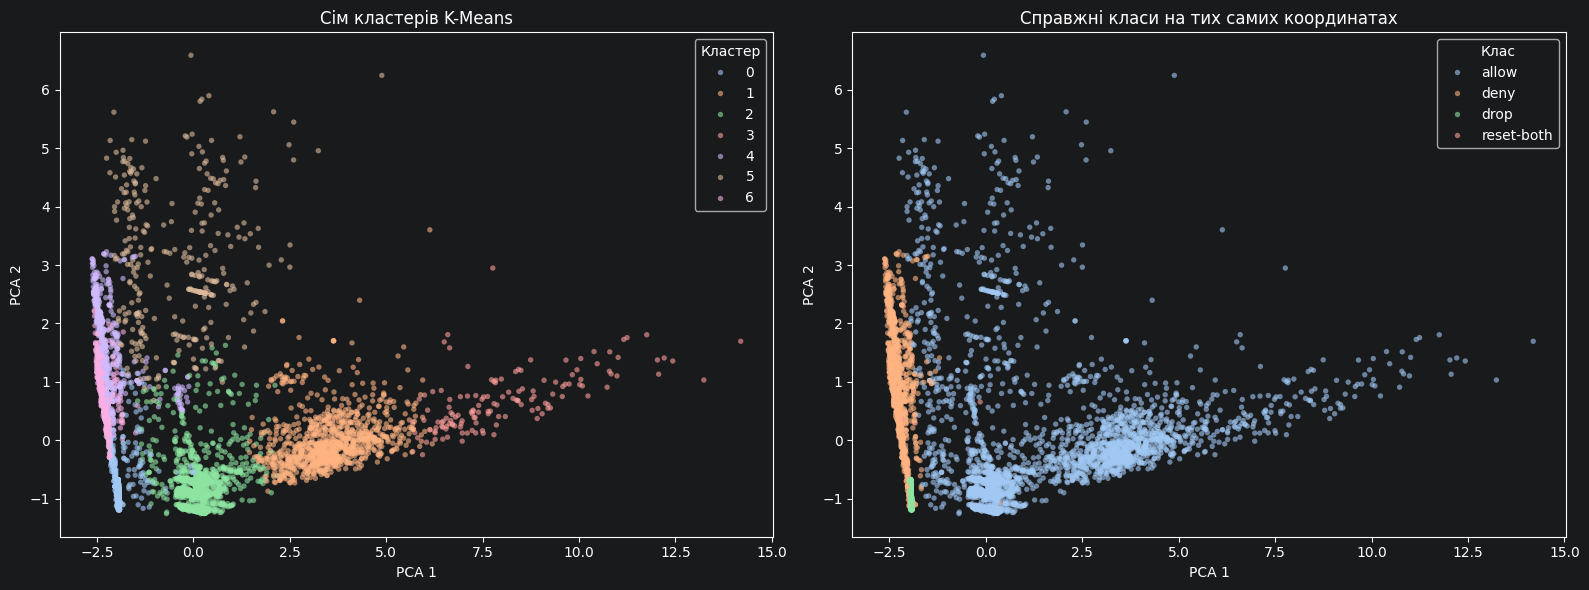

In [45]:
plot_sample = cluster_plot_data.iloc[sample_indices]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=plot_sample, x="PCA 1", y="PCA 2", hue="Кластер",
                hue_order=[str(i) for i in range(7)], palette="pastel",
                s=15, alpha=0.6, linewidth=0, ax=axes[0])

sns.scatterplot(data=plot_sample, x="PCA 1", y="PCA 2", hue="Клас",
                hue_order=class_order, palette="pastel", s=15, alpha=0.6,
                linewidth=0, ax=axes[1])

axes[0].set_title("Сім кластерів K-Means")
axes[1].set_title("Справжні класи на тих самих координатах")

plt.tight_layout()
plt.show()

На графіках бачимо ті самі 5000 записів із різним розфарбуванням: за кластерами та за справжніми класами.
Бачимо, що клас allow розділяється на кілька кластерів, а деякі області різних класів перекриваються. Для точнішого порівняння аналізуємо склад кластерів на всіх записах датасета.

In [46]:
cluster_class_counts = pd.crosstab(cluster_plot_data["Кластер"],
                                   cluster_plot_data["Клас"]).reindex(columns=class_order, fill_value=0)

cluster_class_percent = cluster_class_counts.div(cluster_class_counts.sum(axis=1), axis=0) * 100

print("Кількість записів кожного класу в кластерах:")
display(cluster_class_counts)

print("Склад кожного кластера у відсотках:")
display(cluster_class_percent.round(2))

Кількість записів кожного класу в кластерах:


Клас,allow,deny,drop,reset-both
Кластер,,,,
0,762,2860,12851,4
1,12440,0,0,0
2,18324,8,0,6
3,1879,0,0,0
4,441,5416,0,35
5,3767,0,0,0
6,27,6703,0,9


Склад кожного кластера у відсотках:


Клас,allow,deny,drop,reset-both
Кластер,,,,
0,4.62,17.36,77.99,0.02
1,100.00,0.00,0.00,0.00
2,99.92,0.04,0.00,0.03
3,100.00,0.00,0.00,0.00
4,7.48,91.92,0.00,0.59
5,100.00,0.00,0.00,0.00
6,0.40,99.47,0.00,0.13


Кластери частково відповідають справжнім класам. Кластери 1, 3 і 5 містять лише allow, а кластер 2 - майже повністю allow. У кластерах 4 і 6 переважає deny. Усі записи drop потрапляють у кластер 0, але він також містить інші класи.

Окремого кластера reset-both не отримуємо: його 54 записи розподілені між кластерами 0, 2, 4 і 6 у кількості 4, 6, 35 і 9.
Більшість належить кластеру 4, де переважає deny.

Отже, знайдена структура відображає схожість записів, але не відтворює чотири класи Action один до одного. Це узгоджується з тим, що кластеризацію виконуємо без міток класів.

### Завдання 3. Обробка та класифікація текстових даних

Використовуємо SMS Spam Collection із UCI.
Задача - за текстом повідомлення визначити його клас: ham (звичайне повідомлення) або spam (спам).
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

Класично завантажуємо дані, перевіряємо їхній розмір, розподіл класів і переглядаємо приклади повідомлень.

In [47]:
sms_df = pd.read_csv("../Datasets/SMSSpamCollection", sep="\t", header=None, names=["label", "text"], quoting=csv.QUOTE_NONE, encoding="utf-8")

print("Розмір текстового датасета:", sms_df.shape)

print(f"\nКількість повідомлень кожного класу: {sms_df["label"].value_counts()}")

sms_df.head()

Розмір текстового датасета: (5574, 2)

Кількість повідомлень кожного класу: label
ham     4827
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


У датасеті переважають звичайні повідомлення, а частка спаму становить 13,4%. Перед обробкою перевіряємо пропуски, порожні тексти та повтори повідомлень.

In [48]:
print("Кількість пропусків у колонках:", sms_df[["label", "text"]].isna().sum())

print("Порожніх текстів або текстів лише з пробілами:", sms_df["text"].str.strip().eq("").sum())

print("Точних повторів тексту з тією самою міткою:", sms_df.duplicated(subset=["label", "text"]).sum())

Кількість пропусків у колонках: label    0
text     0
dtype: int64
Порожніх текстів або текстів лише з пробілами: 0
Точних повторів тексту з тією самою міткою: 403


In [49]:
sms_prepared = sms_df.drop_duplicates(subset=["label", "text"]).copy()

print("Кількість записів після видалення точних повторів:", len(sms_prepared))

sms_prepared["text_clean"] = (
    sms_prepared["text"]
    .str.lower()
    .str.replace("&lt;", " ", regex=False)
    .str.replace("&gt;", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Повторів із тією самою міткою після очищення:", sms_prepared.duplicated(subset=["label", "text_clean"]).sum())

sms_prepared[["label", "text", "text_clean"]].head()

Кількість записів після видалення точних повторів: 5171
Повторів із тією самою міткою після очищення: 12


,label,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."


In [50]:
sms_prepared = sms_prepared.drop_duplicates(subset=["label", "text_clean"]).copy()

print("Кількість записів:", len(sms_prepared))
print("Повторів із тією самою міткою:", sms_prepared.duplicated(subset=["label", "text_clean"]).sum())

Кількість записів: 5159
Повторів із тією самою міткою: 0


Видалили 403 точні повтори та ще 12 повторних записів після очищення повідомлень. Для подальшої роботи залишається 5159 повідомлень.

Розділяємо очищені повідомлення на навчальну та тестову вибірки. Зберігаємо приблизні частки ham і spam в обох вибірках. Навчальні тексти використовуємо для побудови хмар слів і навчання моделі, а тестові залишаємо для фінального оцінювання.

In [51]:
sms_train, sms_test = train_test_split(sms_prepared, test_size=0.2, stratify=sms_prepared["label"], random_state=7)

print("Повідомлень для навчання:", len(sms_train))
print("Повідомлень для тестування:", len(sms_test))

pd.DataFrame({
    "Навчальна вибірка": sms_train["label"].value_counts(),
    "Тестова вибірка": sms_test["label"].value_counts()})

Повідомлень для навчання: 4127
Повідомлень для тестування: 1032


,Навчальна вибірка,Тестова вибірка
label,,
ham,3613,904
spam,514,128


Будуємо окремі хмари слів для навчальних повідомлень класів ham і spam. Пропускаємо поширені англійські стоп-слова, наприклад "the" та "and", щоб краще побачити зміст повідомлень. Порівнюємо, які слова помітні в обох класах, а які - переважно в одному.

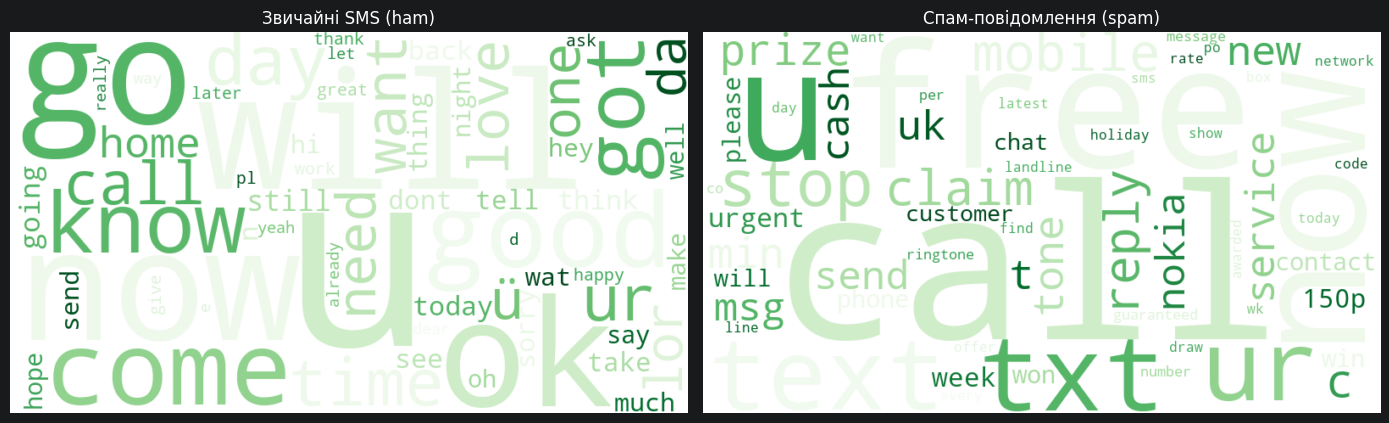

In [52]:
ham_text = " ".join(sms_train.loc[sms_train["label"] == "ham", "text_clean"])
spam_text = " ".join(sms_train.loc[sms_train["label"] == "spam", "text_clean"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, text, title in zip(axes, [ham_text, spam_text], ["Звичайні SMS (ham)", "Спам-повідомлення (spam)"]):
    cloud = WordCloud(width=800, height=450, background_color="white", colormap="Greens",
                      stopwords=STOPWORDS, collocations=False, max_words=60, random_state=7).generate(text)

    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

У звичайних SMS (ham) бачимо розмовні слова й скорочення u, ok, come, go, home. У спамі (spam) виділяються call, free, txt, reply, claim, prize. За ними помічаємо типову пропозицію або заклик до дії - зателефонувати, відповісти чи отримати приз. Слова u, now і call бачимо в обох хмарах, тому за одним таким словом складно визначити клас повідомлення.

Далі перетворюємо тексти SMS на числові ознаки за допомогою TF-IDF. Словник і ваги слів визначаємо на навчальній вибірці. Для тестових SMS використовуємо той самий словник і ваги.

In [53]:
vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")

X_train_tfidf = vectorizer.fit_transform(sms_train["text_clean"])
X_test_tfidf = vectorizer.transform(sms_test["text_clean"])

print("Розмір навчальної матриці:", X_train_tfidf.shape)
print("Розмір тестової матриці:", X_test_tfidf.shape)

Розмір навчальної матриці: (4127, 7745)
Розмір тестової матриці: (1032, 7745)


Навчаємо наївний баєсівський класифікатор на TF-IDF ознаках навчальних SMS. Потім прогнозуємо клас кожного повідомлення з тестової вибірки.

In [54]:
sms_model = MultinomialNB()
sms_model.fit(X_train_tfidf, sms_train["label"])

sms_predictions = sms_model.predict(X_test_tfidf)
print("Кількість прогнозів:", len(sms_predictions))

Кількість прогнозів: 1032


Тепер порівнюємо прогнози зі справжніми мітками тестових SMS. За матрицею помилок визначаємо, скільки спаму модель розпізнала і скільки віднесла до звичайних повідомлень.

In [55]:
labels = ["ham", "spam"]
matrix = confusion_matrix(sms_test["label"], sms_predictions, labels=labels)

pd.DataFrame(matrix,
             index=pd.Index(labels, name="Справжній клас"),
             columns=pd.Index(labels, name="Прогноз моделі"))

Прогноз моделі,ham,spam
Справжній клас,,
ham,904,0
spam,44,84


Бачимо, що на тестовій вибірці модель правильно розпізнала всі 904 звичайні SMS. Зі 128 спам-повідомлень вона виявила 84, а 44 пропустила. Отже, приблизно третина спаму пройшла б через такий фільтр.

In [56]:
print("Оцінка класифікації тестових SMS:")
print(classification_report(sms_test["label"], sms_predictions, labels=labels, digits=3))

Оцінка класифікації тестових SMS:
              precision    recall  f1-score   support

         ham      0.954     1.000     0.976       904
        spam      1.000     0.656     0.792       128

    accuracy                          0.957      1032
   macro avg      0.977     0.828     0.884      1032
weighted avg      0.959     0.957     0.953      1032



Отримуємо accuracy 95,7%, оскільки в тестовій вибірці переважають звичайні SMS і модель правильно розпізнала їх усі. Для оцінки спам-фільтра дивимося також на recall класу spam: модель виявила 65,6% спаму, тобто пропустила приблизно кожне третє спам-повідомлення.

## Висновки

У цій лабораторній роботі дослідили дані мережевого трафіку за допомогою PCA, t-SNE та K-Means, а також навчили модель розпізнавати спам у SMS.

Спочатку застосували PCA та зменшили кількість вимірів з 11 до 6. Після цього дерево рішень навчалося довше, а точність знизилася з 99,73% до 99,65%. Найпомітнішу різницю побачили для класу reset-both: до PCA дерево розпізнало 6 із 11 записів, а після PCA лише один. Також побудували графік t-SNE і побачили, що класи частково перекриваються.

Далі групували записи трафіку за допомогою K-Means. За оцінкою Silhouette Score обрали сім кластерів і порівняли їх зі справжніми класами. Виявили часткову відповідність: три кластери містили лише записи allow, а записи reset-both потрапили до чотирьох різних кластерів.

Згодом було обрано інший датасет із текстами SMS, побудували хмари слів для ham і spam та перетворили повідомлення на числові ознаки за допомогою TF-IDF. На цих ознаках навчили наївний баєсівський класифікатор. На тестовій вибірці модель правильно визначила всі 904 звичайні SMS та 84 зі 128 спам-повідомлень. Загальна точність склала 95,7%, хоча модель пропустила приблизно третину спаму.